# Housing metadata model: walkthrough

This notebook explains **why** the metadata model exists and **how** it works, using the
sample data in this repo. Every chart is produced by the real pipeline
(`housing_meta.build`), not a mock-up.

**The idea in one sentence:** province differences live in *rows of metadata*, not in
*code*. So the yearly maintenance job is editing a few CSV rows, not rewriting a
pipeline.

| Section | What it shows |
|---|---|
| 1. The problem | Three provinces deliver the same concepts with different column names and codes |
| 2. The metadata | The handful of CSVs that hold every province-specific fact |
| 3. Build | One generic load, the same SQL for every province |
| 4. Lineage | Where every canonical variable came from, per province and year |
| 5. Harmonised output | Province codes turned into canonical, labelled values |
| 6. Analysis | Cross-province queries with no `CASE province WHEN ...` anywhere |
| 7. QA | Built-in checks that say exactly what needs a metadata edit |
| 8. The annual cycle | 2026 arrives: a renamed column, a new code and a new province, all handled with CSV rows only |

> Run with `uv sync --group demo` and then `uv run jupyter lab`, and open
> `notebooks/walkthrough.ipynb`. The notebook works on a **temporary copy** of
> `metadata/` and `data/raw/` with an in-memory DuckDB, so it never changes the repo.

In [1]:
import shutil
import tempfile
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
from matplotlib.patches import Patch, Rectangle

from housing_meta import build

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
WORK = Path(tempfile.mkdtemp(prefix="housing_demo_"))
META = WORK / "metadata"
RAW = WORK / "raw"
shutil.copytree(ROOT / "metadata", META)
shutil.copytree(ROOT / "data" / "raw", RAW)

pd.set_option("display.max_colwidth", 60)

In [2]:
# Chart styling: one palette for the whole notebook.
# A province always keeps the same colour, in every chart.
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
PROV = {"ON": CAT[0], "BC": CAT[1], "NS": CAT[2], "MB": CAT[3]}
GOOD, CRITICAL = "#0ca30c", "#d03b3b"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 10, "legend.frameon": False,
})

def q(con, sql, params=None):
    "Run SQL and return a DataFrame."
    return con.execute(sql, params or []).df()

## 1. The problem: same concepts, different deliveries

Each province sends a Parquet file every year. They all describe households (tenure,
dwelling type, shelter cost and so on), but every province names and codes things its
own way, and those choices change over time.

In [3]:
files = sorted(RAW.rglob("*.parquet"))
schemas = pd.DataFrame(
    {
        "file": f.relative_to(RAW).parent.as_posix(),
        "columns": ", ".join(pq.read_schema(f).names),
    }
    for f in files
)
schemas

,file,columns
0,year=2024/province=BC,"HHID, TEN, DTYPE, BEDRMS, HHSIZE, SHLCO, CHN, REGION_INT..."
1,year=2024/province=NS,"household_id, tenure, dwelling_type, bedrooms, household..."
2,year=2024/province=ON,"hh_id, tenure_cd, dwelling, bedrooms, hh_size, shelter_c..."
3,year=2025/province=BC,"HHID, TEN, DTYPE, BEDRMS, HHSIZE, SHLCO, CHN, REGION_INT..."
4,year=2025/province=NS,"household_id, tenure, dwelling_type, bedrooms, household..."
5,year=2025/province=ON,"hh_id, tenure_cd, dwelling, bedrooms, hh_size, monthly_s..."


Things to notice:

* **Names differ.** Tenure is `tenure_cd` in ON, `TEN` in BC and `tenure` in NS.
* **Names change.** ON renamed `shelter_cost_mth` to `monthly_shelter_cost` in 2025.
* **Variables appear.** Period of construction only exists from 2025.
* **Junk turns up.** BC sends an internal `REGION_INTERNAL` column nobody asked for.

Codes differ too. Here is the raw tenure column in each 2025 file. To draw even this
simple chart *without* the model, you have to hard-code which column to read for
each province. **This dictionary is the kind of logic the model removes:**

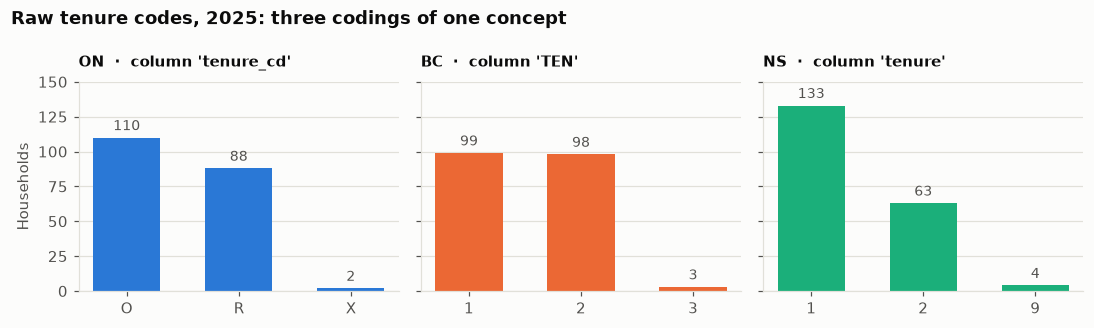

In [4]:
# The anti-pattern: province-specific knowledge living in code.
RAW_TENURE_COLUMN = {"ON": "tenure_cd", "BC": "TEN", "NS": "tenure"}

fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for ax, (prov, col) in zip(axes, RAW_TENURE_COLUMN.items()):
    path = RAW / "year=2025" / f"province={prov}" / "households.parquet"
    counts = (
        duckdb.sql(f"SELECT CAST({col} AS VARCHAR) AS v, count(*) AS n "
                   f"FROM '{path.as_posix()}' GROUP BY 1 ORDER BY 1").df()
    )
    ax.bar(counts.v, counts.n, color=PROV[prov], width=0.6)
    for x, n in zip(counts.v, counts.n):
        ax.text(x, n + 3, str(n), ha="center", va="bottom", color=INK2, fontsize=9)
    ax.set_title(f"{prov}  ·  column '{col}'", fontsize=10)
    ax.set_ylim(0, 150)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Households")
fig.suptitle("Raw tenure codes, 2025: three codings of one concept", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()

`O`/`R`/`X`, `1`/`2`/`3` and `1`/`2`/`9` all mean roughly *owner / renter / other*.
With five variables, three provinces and annual changes, hand-written recoding like
this soon becomes the most fragile part of the pipeline.

## 2. The metadata: everything province-specific is a row

The model splits knowledge into three groups of tables:

```mermaid
erDiagram
    codeset ||--o{ code : contains
    codeset ||--o{ variable : "codes for"
    variable ||--o{ source_column_map : "is called"
    variable ||--o{ source_code_map : "recodes"
    dataset ||--o{ dataset_column : "has columns"
    variable ||--o{ dataset_column : "mapped to"
    dataset ||--o{ record_value : contains
    variable ||--o{ record_value : describes
```

| Group | Tables | Who maintains it | Changes when |
|---|---|---|---|
| **Reference** (what we *mean*) | `codeset`, `code`, `variable` | Subject-matter owners, CSV in git | The concept changes (new variable, new code) |
| **Mapping** (what each province *calls* it) | `source_column_map`, `source_code_map` | Data team, CSV in git | A province changes its delivery |
| **Production** (what was *loaded*) | `dataset`, `dataset_column`, `record_value` | The pipeline | Every load, written automatically |

Every metadata row has `valid_from_year` / `valid_to_year`. One rule,
`reference_year BETWEEN valid_from_year AND coalesce(valid_to_year, 9999)`, handles
renames, new variables and retired codes.

The canonical variables:

In [5]:
pd.read_csv(META / "variable.csv", dtype=str, keep_default_na=False)

,variable_id,variable_name,label_en,role,data_type,codeset_id,unit,valid_from_year,valid_to_year
0,HH_ID,household_id,Household identifier,key,VARCHAR,,,2020,
1,TENURE,tenure,Tenure of dwelling,attribute,VARCHAR,TENURE,,2020,
2,DWELL_TYPE,dwelling_type,Structural type of dwelling,attribute,VARCHAR,DWELL_TYPE,,2020,
3,BEDROOMS,bedrooms,Number of bedrooms,attribute,INTEGER,,count,2020,
4,HH_SIZE,household_size,Number of persons in household,attribute,INTEGER,,persons,2020,
5,SHELTER_COST,monthly_shelter_cost,Monthly shelter cost,attribute,DECIMAL,,CAD/month,2020,
6,CORE_NEED,core_housing_need,Household is in core housing need,attribute,VARCHAR,YES_NO,,2020,
7,PERIOD_BUILT,period_built,Period of construction,attribute,VARCHAR,PERIOD_BUILT,,2025,


How each province names them. Note the two ON rows for `SHELTER_COST`: the rename is
*data*, with a validity range, not an `if year >= 2025` in code.

In [6]:
scm = pd.read_csv(META / "source_column_map.csv", dtype=str, keep_default_na=False)
scm[scm.variable_id.isin(["TENURE", "SHELTER_COST"])]

,source_system,source_column,variable_id,valid_from_year,valid_to_year,notes
1,ON,tenure_cd,TENURE,2020,,
5,ON,shelter_cost_mth,SHELTER_COST,2020,2024,Renamed in 2025
6,ON,monthly_shelter_cost,SHELTER_COST,2025,,
10,BC,TEN,TENURE,2020,,
14,BC,SHLCO,SHELTER_COST,2020,,
18,NS,tenure,TENURE,2020,,
22,NS,monthly_shelter_cost,SHELTER_COST,2020,,


How province codes become canonical codes. NS already uses canonical codes, so it has
**no rows** here: if a province has no code map for a variable, its values pass
through unchanged.

In [7]:
codemap = pd.read_csv(META / "source_code_map.csv", dtype=str, keep_default_na=False)
codemap[codemap.variable_id == "TENURE"]

,source_system,variable_id,source_value,code,valid_from_year,valid_to_year
0,ON,TENURE,O,1,2020,
1,ON,TENURE,R,2,2020,
2,ON,TENURE,X,9,2020,
13,BC,TENURE,1,1,2020,
14,BC,TENURE,2,2,2020,


In [8]:
sizes = {p.stem: len(pd.read_csv(p)) for p in sorted(META.glob("*.csv"))}
print("Every province-specific fact in this model, in rows:")
for name, n in sizes.items():
    print(f"  {name:<20} {n:>3}")
print(f"  {'total':<20} {sum(sizes.values()):>3}   (Python with province logic in it: 0 lines)")

Every province-specific fact in this model, in rows:
  code                  12
  codeset                4
  source_code_map       21
  source_column_map     25
  variable               8
  total                 70   (Python with province logic in it: 0 lines)


## 3. Build: one generic load

`build.build()` does the same four steps for every file it finds under
`year=YYYY/province=XX/`:

1. register the file in `dataset`
2. `DESCRIBE` it and join each column to `source_column_map` for that province and year (giving `dataset_column`, the lineage)
3. rename mapped columns to canonical ids and `UNPIVOT` to long form
4. join to `source_code_map` to recode, then insert into `record_value`

Then it creates the views, builds the wide `household_harmonised` table and prints a
QA summary.

In [9]:
con = duckdb.connect()            # in-memory; the CLI does the same against a .duckdb file
build.build(con, META, RAW)

Reference metadata


  meta.codeset                4 rows
  meta.code                  12 rows
  meta.variable               8 rows
  meta.source_column_map     25 rows
  meta.source_code_map       21 rows
Datasets


  BC_2024     200 records   6 variables     1200 values


  NS_2024     200 records   6 variables     1200 values
  ON_2024     200 records   6 variables     1200 values


  BC_2025     200 records   7 variables     1400 values


  NS_2025     200 records   7 variables     1400 values
  ON_2025     200 records   7 variables     1400 values


QA summary


  !!  unmapped_columns   2
  OK  missing_variables  0
  !!  unmapped_values    1
  OK  invalid_codes      0
  OK  bad_numerics       0


The two `!!` lines are planted problems in the sample data (BC's extra column and a BC
tenure code `3` that nobody has mapped). Section 7 covers them.

## 4. Lineage: where every value came from

Because the load records every physical column it sees (`dataset_column`), we can draw
a full lineage map. Each cell shows the **source column** that fed a canonical variable
for one province and year.

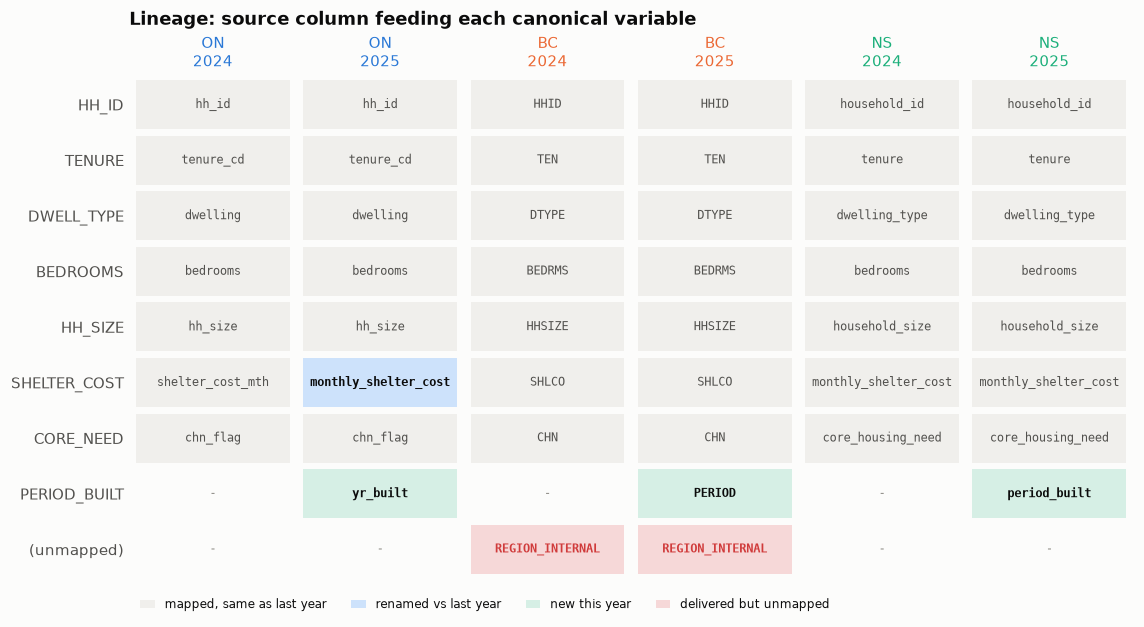

In [10]:
def plot_lineage(con, title):
    lin = q(con, '''
        SELECT d.source_system AS prov, d.reference_year AS year, dc.source_column,
               coalesce(dc.variable_id, '(unmapped)') AS variable_id
        FROM meta.dataset_column dc JOIN meta.dataset d USING (dataset_id)
    ''')
    var_order = q(con, "SELECT variable_id FROM meta.variable").variable_id.tolist()
    var_order += ["(unmapped)"] if (lin.variable_id == "(unmapped)").any() else []
    prov_order = [p for p in PROV if p in set(lin.prov)]
    cols = [(p, y) for p in prov_order for y in sorted(lin.year.unique())
            if ((lin.prov == p) & (lin.year == y)).any()]
    cell = lin.groupby(["variable_id", "prov", "year"]).source_column.agg("\n".join)
    first_year = lin.year.min()

    fig, ax = plt.subplots(figsize=(1.45 * len(cols) + 1.8, 0.5 * len(var_order) + 1.3))
    for j, (p, y) in enumerate(cols):
        prev = (p, y - 1)
        for i, v in enumerate(var_order):
            txt = cell.get((v, p, y))
            if txt is None:
                face, label, color, weight = SURFACE, "-", MUTED, "normal"
            elif v == "(unmapped)":
                face, label, color, weight = "#f6d8d8", txt, CRITICAL, "bold"
            elif prev in cols and cell.get((v, *prev)) not in (None, txt):
                face, label, color, weight = "#cde2fb", txt, INK, "bold"   # renamed
            elif y > first_year and (prev not in cols or cell.get((v, *prev)) is None):
                face, label, color, weight = "#d6efe5", txt, INK, "bold"   # new this year
            else:
                face, label, color, weight = "#f0efec", txt, INK2, "normal"
            ax.add_patch(Rectangle((j + 0.04, i + 0.06), 0.92, 0.88, facecolor=face, edgecolor="none"))
            ax.text(j + 0.5, i + 0.5, label, ha="center", va="center", fontsize=8,
                    color=color, fontweight=weight, family="monospace")
    ax.set_xlim(0, len(cols)); ax.set_ylim(len(var_order), 0)
    ax.set_xticks([j + 0.5 for j in range(len(cols))], [f"{p}\n{y}" for p, y in cols])
    ax.set_yticks([i + 0.5 for i in range(len(var_order))], var_order)
    ax.xaxis.tick_top(); ax.tick_params(length=0); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    for j, (p, _) in enumerate(cols):
        ax.get_xticklabels()[j].set_color(PROV[p])
    ax.legend(handles=[
        Patch(facecolor="#f0efec", label="mapped, same as last year"),
        Patch(facecolor="#cde2fb", label="renamed vs last year"),
        Patch(facecolor="#d6efe5", label="new this year"),
        Patch(facecolor="#f6d8d8", label="delivered but unmapped"),
    ], loc="upper left", bbox_to_anchor=(0, -0.02), ncol=4, fontsize=8, handlelength=1.2)
    ax.set_title(title, pad=34)
    fig.tight_layout()

plot_lineage(con, "Lineage: source column feeding each canonical variable")

The highlighted cells show the year-to-year churn the mapping tables absorb: ON's
shelter-cost rename, `PERIOD_BUILT` arriving in 2025 under three different names, and
BC's unmapped column. None of it needed a code change.

The same lineage, as a query anyone can run:

In [11]:
q(con, '''
    SELECT dc.variable_id, d.reference_year,
           string_agg(d.source_system || ': ' || dc.source_column, '   ' ORDER BY d.source_system) AS source_columns
    FROM meta.dataset_column dc JOIN meta.dataset d USING (dataset_id)
    WHERE dc.variable_id IS NOT NULL
    GROUP BY ALL ORDER BY 1, 2
''')

,variable_id,reference_year,source_columns
0,BEDROOMS,2024,BC: BEDRMS NS: bedrooms ON: bedrooms
1,BEDROOMS,2025,BC: BEDRMS NS: bedrooms ON: bedrooms
2,CORE_NEED,2024,BC: CHN NS: core_housing_need ON: chn_flag
3,CORE_NEED,2025,BC: CHN NS: core_housing_need ON: chn_flag
4,DWELL_TYPE,2024,BC: DTYPE NS: dwelling_type ON: dwelling
5,DWELL_TYPE,2025,BC: DTYPE NS: dwelling_type ON: dwelling
6,HH_ID,2024,BC: HHID NS: household_id ON: hh_id
7,HH_ID,2025,BC: HHID NS: household_id ON: hh_id
8,HH_SIZE,2024,BC: HHSIZE NS: household_size ON: hh_size
9,HH_SIZE,2025,BC: HHSIZE NS: household_size ON: hh_size


## 5. Harmonised output: one shape for everything

All values land in **one long table**, `record_value`: one row per record × variable,
keeping both what the province sent (`source_value`) and the canonical `value`. The
view `v_record_labelled` adds the variable label, unit and code label. This is the
"seamless join".

One ON household, fully described:

In [12]:
q(con, '''
    SELECT variable_label, source_value, value, value_label, unit, mapped_via
    FROM meta.v_record_labelled
    WHERE dataset_id = 'ON_2025' AND record_id = 'ON202500000'
    ORDER BY variable_id
''')

,variable_label,source_value,value,value_label,unit,mapped_via
0,Number of bedrooms,4,4,NaN,count,passthrough
1,Household is in core housing need,N,0,No,NaN,code_map
2,Structural type of dwelling,SD,1,Single-detached house,NaN,code_map
3,Number of persons in household,4,4,NaN,persons,passthrough
4,Period of construction,1980-1999,2,1980 to 1999,NaN,code_map
5,Monthly shelter cost,3192.34,3192.34,NaN,CAD/month,passthrough
6,Tenure of dwelling,O,1,Owner,NaN,code_map


And the chart from section 1, redrawn from the harmonised view. **No province
dictionary this time:** the query only says `variable_id = 'TENURE'`.

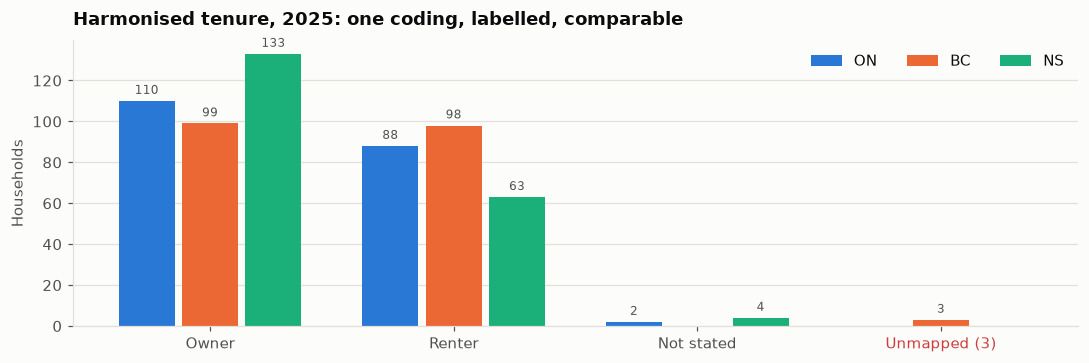

In [13]:
ten = q(con, '''
    SELECT source_system AS prov,
           coalesce(value_label, 'Unmapped (' || source_value || ')') AS tenure,
           count(*) AS n
    FROM meta.v_record_labelled
    WHERE variable_id = 'TENURE' AND reference_year = 2025
    GROUP BY ALL
''')
labels = ["Owner", "Renter", "Not stated"] + sorted(t for t in ten.tenure.unique() if t.startswith("Unmapped"))
provs = [p for p in PROV if p in set(ten.prov)]
w = 0.26

fig, ax = plt.subplots(figsize=(10, 3.4))
for k, prov in enumerate(provs):
    s = ten[ten.prov == prov].set_index("tenure").n.reindex(labels).fillna(0)
    xs = [i + (k - 1) * w for i in range(len(labels))]
    ax.bar(xs, s.values, width=w - 0.03, color=PROV[prov], label=prov)
    for x, n in zip(xs, s.values):
        if n:
            ax.text(x, n + 2, f"{n:.0f}", ha="center", va="bottom", fontsize=8, color=INK2)
ax.set_xticks(range(len(labels)), labels)
ax.get_xticklabels()[-1].set_color(CRITICAL)
ax.set_ylabel("Households")
ax.grid(axis="x", visible=False)
ax.legend(ncol=3, loc="upper right")
ax.set_title("Harmonised tenure, 2025: one coding, labelled, comparable")
fig.tight_layout()

BC's code `3` has no mapping, so it shows up as **Unmapped (3)** instead of
silently becoming a wrong category or vanishing. Section 8 fixes it with one CSV row.

For analysts who want ordinary columns, the build also generates
`household_harmonised`: one typed row per record. Its column list is **generated from
the `variable` table**, so a new variable becomes a new column automatically.

In [14]:
q(con, "SELECT * FROM meta.household_harmonised ORDER BY reference_year, source_system LIMIT 5")

,reference_year,source_system,dataset_id,record_id,bedrooms,core_housing_need,dwelling_type,household_size,period_built,monthly_shelter_cost,tenure
0,2024,BC,BC_2024,202400004,1,0,3,6,None,1836.95,2
1,2024,BC,BC_2024,202400011,5,0,1,3,None,3264.45,2
2,2024,BC,BC_2024,202400013,2,0,3,6,None,1840.67,2
3,2024,BC,BC_2024,202400019,1,1,1,2,None,2067.72,1
4,2024,BC,BC_2024,202400020,3,0,1,6,None,2566.05,2


## 6. Analysis with zero province logic

The two queries below cover every province and year, and will keep doing so for new
ones, because they only use canonical names and the code tables.

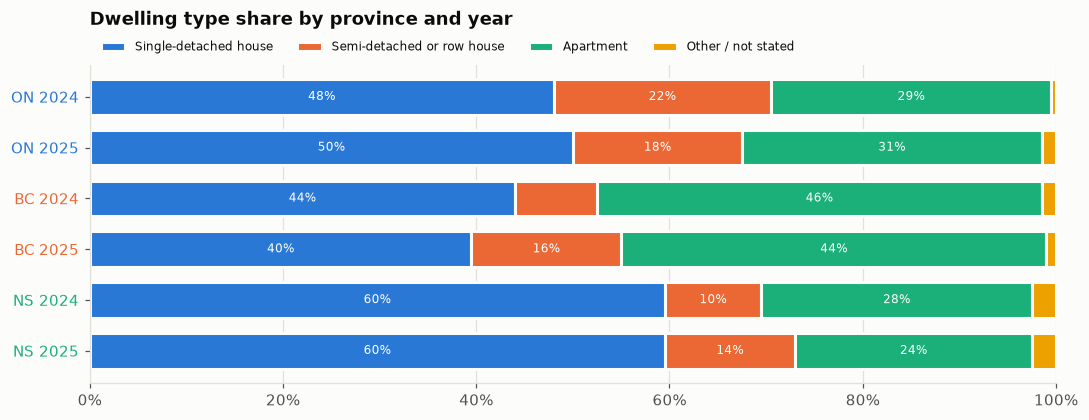

In [15]:
DWELL_SQL = '''
    SELECT h.reference_year AS year, h.source_system AS prov,
           coalesce(c.label_en, 'Unmapped') AS dwelling, c.sort_order, count(*) AS n
    FROM meta.household_harmonised h
    JOIN meta.variable v ON v.variable_id = 'DWELL_TYPE'
    LEFT JOIN meta.code c
      ON c.codeset_id = v.codeset_id AND c.code = h.dwelling_type
     AND h.reference_year BETWEEN c.valid_from_year AND coalesce(c.valid_to_year, 9999)
    GROUP BY ALL
'''

def plot_dwelling(con, title):
    d = q(con, DWELL_SQL)
    d["share"] = d.n / d.groupby(["year", "prov"]).n.transform("sum")
    cats = d.sort_values("sort_order").dwelling.drop_duplicates().tolist()
    rows = sorted({(p, y) for p, y in zip(d.prov, d.year)},
                  key=lambda r: (list(PROV).index(r[0]), r[1]))
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(rows) + 1.4))
    left = [0.0] * len(rows)
    for k, cat in enumerate(cats):
        vals = [d[(d.prov == p) & (d.year == y) & (d.dwelling == cat)].share.sum() for p, y in rows]
        ax.barh(range(len(rows)), vals, left=left, height=0.7, color=CAT[k],
                edgecolor=SURFACE, linewidth=2, label=cat)
        for i, (l, v) in enumerate(zip(left, vals)):
            if v >= 0.09:
                ax.text(l + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white")
        left = [l + v for l, v in zip(left, vals)]
    ax.set_yticks(range(len(rows)), [f"{p} {y}" for p, y in rows])
    for i, (p, _) in enumerate(rows):
        ax.get_yticklabels()[i].set_color(PROV[p])
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
    ax.grid(axis="y", visible=False)
    ax.legend(ncol=len(cats), loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8)
    ax.set_title(title, pad=26)
    fig.tight_layout()

plot_dwelling(con, "Dwelling type share by province and year")

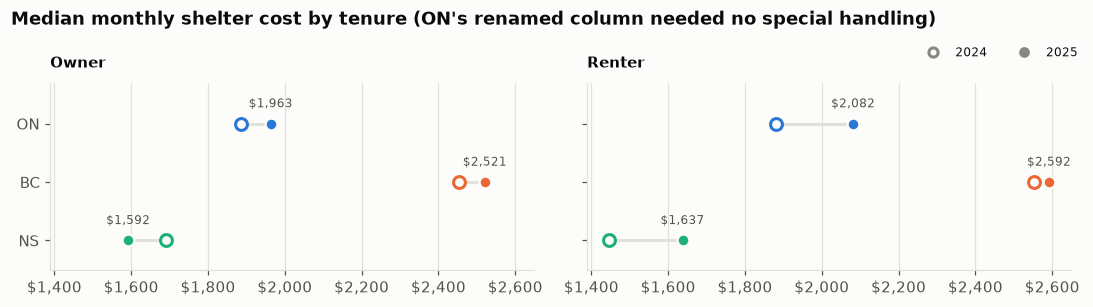

In [16]:
cost = q(con, '''
    SELECT h.reference_year AS year, h.source_system AS prov, c.label_en AS tenure,
           median(h.monthly_shelter_cost) AS median_cost
    FROM meta.household_harmonised h
    JOIN meta.code c ON c.codeset_id = 'TENURE' AND c.code = h.tenure
    WHERE c.label_en IN ('Owner', 'Renter')
    GROUP BY ALL
''')

fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharex=True, sharey=True)
provs = [p for p in PROV if p in set(cost.prov)]
for ax, tenure in zip(axes, ["Owner", "Renter"]):
    for i, prov in enumerate(provs):
        s = cost[(cost.prov == prov) & (cost.tenure == tenure)].set_index("year").median_cost
        ax.plot([s[2024], s[2025]], [i, i], color=GRID, linewidth=2, zorder=1)
        ax.scatter(s[2024], i, s=60, facecolor=SURFACE, edgecolor=PROV[prov], linewidth=2, zorder=2)
        ax.scatter(s[2025], i, s=60, color=PROV[prov], edgecolor=SURFACE, linewidth=1.5, zorder=3)
        ax.text(s[2025], i - 0.28, f"${s[2025]:,.0f}", ha="center", fontsize=8, color=INK2)
    ax.set_title(tenure, fontsize=10)
    ax.set_yticks(range(len(provs)), provs)
    ax.set_ylim(len(provs) - 0.5, -0.7)
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))
fig.legend(handles=[
    plt.Line2D([], [], marker="o", ls="", markerfacecolor=SURFACE, markeredgecolor=MUTED, markeredgewidth=2, label="2024"),
    plt.Line2D([], [], marker="o", ls="", color=MUTED, label="2025"),
], loc="upper right", bbox_to_anchor=(0.99, 0.9), ncol=2, fontsize=8)
fig.suptitle("Median monthly shelter cost by tenure (ON's renamed column needed no special handling)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()

The data dictionary is just as generic. Here is what changed between 2024 and 2025,
taken straight from `v_data_dictionary`:

In [17]:
q(con, '''
    SELECT variable_id, variable_label, code, code_label
    FROM meta.v_data_dictionary WHERE reference_year = 2025
    EXCEPT
    SELECT variable_id, variable_label, code, code_label
    FROM meta.v_data_dictionary WHERE reference_year = 2024
    ORDER BY ALL
''')

,variable_id,variable_label,code,code_label
0,PERIOD_BUILT,Period of construction,1,Before 1980
1,PERIOD_BUILT,Period of construction,2,1980 to 1999
2,PERIOD_BUILT,Period of construction,3,2000 or later


## 7. QA: the model tells you what to edit

Because the load is generic, the checks are generic too. Each QA view should be empty
on a clean build, and each one points to a specific metadata fix:

| Check | Means | Fix |
|---|---|---|
| `unmapped_columns` | A province sent a column nobody mapped | Add a `source_column_map` row |
| `missing_variables` | A variable valid this year is missing from a file | Usually a rename: close the old mapping row, add the new one |
| `unmapped_values` | A province sent a code with no `source_code_map` row | Add a `source_code_map` row (and a `code` row if it's new) |
| `invalid_codes` | A canonical value isn't in the codeset for that year | Fix the map's target code, or extend `code` validity |
| `bad_numerics` | A numeric variable has values that don't cast | Talk to the province |

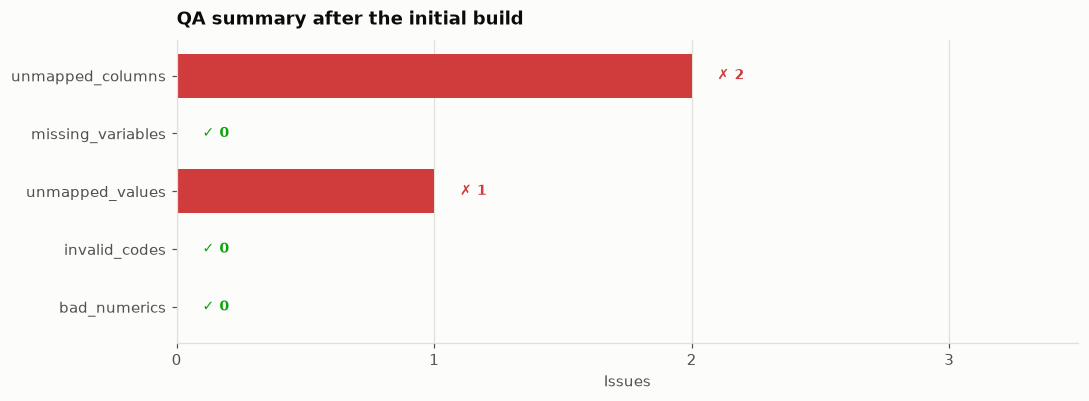

In [18]:
def qa(con):
    return q(con, "SELECT * FROM meta.v_qa_summary")

def plot_qa(frames, title):
    "frames: {stage label: qa dataframe}. One bar per check per stage."
    checks = next(iter(frames.values())).check_name.tolist()
    n = len(frames)
    h = 0.8 / n
    fig, ax = plt.subplots(figsize=(10, 0.55 * len(checks) * max(n, 1.4) / 1.4 + 1))
    for k, (stage, df) in enumerate(frames.items()):
        vals = df.set_index("check_name").n_issues.reindex(checks)
        ys = [i + (k - (n - 1) / 2) * h for i in range(len(checks))]
        color = CAT[k] if n > 1 else [CRITICAL if v else GOOD for v in vals]
        ax.barh(ys, vals, height=h - 0.04, color=color, label=stage if n > 1 else None)
        for y, v in zip(ys, vals):
            mark, c = ("✓ 0", GOOD) if v == 0 else (f"✗ {v}", CRITICAL)
            ax.text(v + 0.1, y, mark, va="center", fontsize=9, color=c, fontweight="bold")
    ax.set_yticks(range(len(checks)), checks)
    ax.invert_yaxis()
    ax.set_xlabel("Issues")
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.set_xlim(0, max(max(df.n_issues) for df in frames.values()) + 1.5)
    ax.grid(axis="y", visible=False)
    if n > 1:
        ax.legend(loc="lower right")
    ax.set_title(title)
    fig.tight_layout()

qa_2025 = qa(con)
plot_qa({"2024-2025 sample": qa_2025}, "QA summary after the initial build")

In [19]:
q(con, "SELECT * FROM meta.v_qa_unmapped_columns")

,source_system,reference_year,dataset_id,source_column,source_type
0,BC,2024,BC_2024,REGION_INTERNAL,VARCHAR
1,BC,2025,BC_2025,REGION_INTERNAL,VARCHAR


In [20]:
q(con, "SELECT * FROM meta.v_qa_unmapped_values")

,reference_year,source_system,dataset_id,variable_id,source_value,n_records
0,2025,BC,BC_2025,TENURE,3,3


These are the planted problems: BC's `REGION_INTERNAL` column (2 files) and BC 2025's
tenure code `3` (3 records). The QA output gives the exact province, year, variable and
value, which is all you need to write the fix.

## 8. The annual cycle: 2026 arrives

This is the part that matters for maintenance. We'll simulate a realistic 2026
delivery:

* **ON renames** `tenure_cd` to `tenure_code`.
* **BC** still sends tenure code `3` and the `REGION_INTERNAL` column.
* **Manitoba (MB) joins**, with its own column names *and* its own codes.
* NS sends the same as last year.

Then we'll go through the normal workflow: **load, read the QA, edit CSV rows,
reload**. No Python changes.

In [21]:
import random
import pyarrow as pa
from housing_meta import generate_sample as gs

def write(prov, year, table):
    out = RAW / f"year={year}" / f"province={prov}" / "households.parquet"
    out.parent.mkdir(parents=True, exist_ok=True)
    pq.write_table(table, out)

Y = 2026
write("ON", Y, gs._on(Y, random.Random(f"ON{Y}")).rename_columns(
    {"tenure_cd": "tenure_code"}))                                  # the rename
write("BC", Y, gs._bc(Y, random.Random(f"BC{Y}")))
write("NS", Y, gs._ns(Y, random.Random(f"NS{Y}")))

rng, N = random.Random("MB2026"), 200                               # a brand-new province
write("MB", Y, pa.table({
    "HOUSEHOLD_KEY":        [f"MB-{i:06d}" for i in range(N)],
    "TENURE_TYPE":          rng.choices(["OWN", "RENT", "UNK"], [62, 36, 2], k=N),
    "STRUCT":               rng.choices(["SINGLE", "SEMI_ROW", "APT", "OTHER"], [58, 10, 30, 2], k=N),
    "BEDROOM_CT":           [rng.randint(0, 5) for _ in range(N)],
    "PERSONS":              [rng.randint(1, 6) for _ in range(N)],
    "SHELTER_COST_MONTHLY": [round(rng.uniform(550, 2900), 2) for _ in range(N)],
    "CHN_IND":              rng.choices(["T", "F"], [11, 89], k=N),
    "BUILT_PERIOD":         rng.choices(["A", "B", "C"], k=N),
}))

for f in sorted(RAW.glob(f"year={Y}/*/*.parquet")):
    print(f.relative_to(RAW).parent.as_posix(), "->", ", ".join(pq.read_schema(f).names))

year=2026/province=BC -> HHID, TEN, DTYPE, BEDRMS, HHSIZE, SHLCO, CHN, REGION_INTERNAL, PERIOD
year=2026/province=MB -> HOUSEHOLD_KEY, TENURE_TYPE, STRUCT, BEDROOM_CT, PERSONS, SHELTER_COST_MONTHLY, CHN_IND, BUILT_PERIOD
year=2026/province=NS -> household_id, tenure, dwelling_type, bedrooms, household_size, monthly_shelter_cost, core_housing_need, period_built
year=2026/province=ON -> hh_id, tenure_code, dwelling, bedrooms, hh_size, monthly_shelter_cost, chn_flag, yr_built


### Step 1: load 2026 with **no** metadata changes

The pipeline doesn't crash or guess. It loads what it can and the QA lists everything
that needs a decision.

In [22]:
META_BEFORE = WORK / "metadata_before_2026"
shutil.copytree(META, META_BEFORE)        # kept for the "partial reload" example later

con = duckdb.connect()
build.build(con, META, RAW)
qa_2026_raw = qa(con)

Reference metadata
  meta.codeset                4 rows
  meta.code                  12 rows
  meta.variable               8 rows
  meta.source_column_map     25 rows
  meta.source_code_map       21 rows
Datasets


  BC_2024     200 records   6 variables     1200 values
  NS_2024     200 records   6 variables     1200 values
  ON_2024     200 records   6 variables     1200 values


  BC_2025     200 records   7 variables     1400 values
  NS_2025     200 records   7 variables     1400 values
  ON_2025     200 records   7 variables     1400 values
  BC_2026     200 records   7 variables     1400 values


  MB_2026     200 records  no key column mapped - values not loaded (see QA)
  NS_2026     200 records   7 variables     1400 values
  ON_2026     200 records   6 variables     1200 values
QA summary


  !!  unmapped_columns   12
  !!  missing_variables  9
  !!  unmapped_values    2
  OK  invalid_codes      0
  OK  bad_numerics       0


In [23]:
q(con, "SELECT source_system, reference_year, source_column FROM meta.v_qa_unmapped_columns ORDER BY ALL")

,source_system,reference_year,source_column
0,BC,2024,REGION_INTERNAL
1,BC,2025,REGION_INTERNAL
2,BC,2026,REGION_INTERNAL
3,MB,2026,BEDROOM_CT
4,MB,2026,BUILT_PERIOD
5,MB,2026,CHN_IND
6,MB,2026,HOUSEHOLD_KEY
7,MB,2026,PERSONS
8,MB,2026,SHELTER_COST_MONTHLY
9,MB,2026,STRUCT


In [24]:
q(con, "SELECT * FROM meta.v_qa_missing_variables ORDER BY ALL")

,dataset_id,source_system,reference_year,variable_id
0,MB_2026,MB,2026,BEDROOMS
1,MB_2026,MB,2026,CORE_NEED
2,MB_2026,MB,2026,DWELL_TYPE
3,MB_2026,MB,2026,HH_ID
4,MB_2026,MB,2026,HH_SIZE
5,MB_2026,MB,2026,PERIOD_BUILT
6,MB_2026,MB,2026,SHELTER_COST
7,MB_2026,MB,2026,TENURE
8,ON_2026,ON,2026,TENURE


Read together, the QA explains itself:

* `ON tenure_code` is unmapped **and** `ON_2026 TENURE` is missing → that's a rename.
* Eight `MB` columns are unmapped **and** MB is missing every variable → that's a new province.
* `BC TEN = 3` is still unmapped (2025 and 2026).
* `BC REGION_INTERNAL` is still unmapped.

### Step 2: edit metadata rows

Below, a small helper appends or changes rows in the CSVs. In real life this is a pull
request against `metadata/*.csv`, reviewed like any other change.

In [25]:
CHANGES = []

def add_rows(table, rows):
    path = META / f"{table}.csv"
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    new = pd.DataFrame(rows, columns=df.columns).fillna("")
    pd.concat([df, new]).to_csv(path, index=False)
    CHANGES.append(new.assign(change="added").assign(table=table))

def close_row(table, where, valid_to_year, note=""):
    path = META / f"{table}.csv"
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    mask = pd.concat([df[k] == v for k, v in where.items()], axis=1).all(axis=1)
    assert mask.sum() == 1, f"expected exactly one row to close, matched {mask.sum()}"
    df.loc[mask, "valid_to_year"] = str(valid_to_year)
    if note and "notes" in df:
        df.loc[mask, "notes"] = note
    df.to_csv(path, index=False)
    CHANGES.append(df[mask].assign(change="closed").assign(table=table))

In [26]:
# 1. ON rename: close the old mapping, open the new one
close_row("source_column_map", {"source_system": "ON", "source_column": "tenure_cd"}, 2025, "Renamed in 2026")
add_rows("source_column_map", [["ON", "tenure_code", "TENURE", "2026", "", ""]])

# 2. BC tenure '3': agree a new canonical code with the subject-matter owner, valid from 2025
add_rows("code",            [["TENURE", "3", "Other tenure (e.g. band housing)", "3", "2025", ""]])
add_rows("source_code_map", [["BC", "TENURE", "3", "3", "2025", ""]])

# 3. New province: map its columns...
add_rows("source_column_map", [
    ["MB", "HOUSEHOLD_KEY",        "HH_ID",        "2026", "", ""],
    ["MB", "TENURE_TYPE",          "TENURE",       "2026", "", ""],
    ["MB", "STRUCT",               "DWELL_TYPE",   "2026", "", ""],
    ["MB", "BEDROOM_CT",           "BEDROOMS",     "2026", "", ""],
    ["MB", "PERSONS",              "HH_SIZE",      "2026", "", ""],
    ["MB", "SHELTER_COST_MONTHLY", "SHELTER_COST", "2026", "", ""],
    ["MB", "CHN_IND",              "CORE_NEED",    "2026", "", ""],
    ["MB", "BUILT_PERIOD",         "PERIOD_BUILT", "2026", "", ""],
])
# ...and its codes
add_rows("source_code_map", [["MB", var, src, code, "2026", ""] for var, src, code in [
    ("TENURE", "OWN", "1"), ("TENURE", "RENT", "2"), ("TENURE", "UNK", "9"),
    ("DWELL_TYPE", "SINGLE", "1"), ("DWELL_TYPE", "SEMI_ROW", "2"),
    ("DWELL_TYPE", "APT", "3"), ("DWELL_TYPE", "OTHER", "9"),
    ("CORE_NEED", "T", "1"), ("CORE_NEED", "F", "0"),
    ("PERIOD_BUILT", "A", "1"), ("PERIOD_BUILT", "B", "2"), ("PERIOD_BUILT", "C", "3"),
]])

changes = pd.concat(CHANGES, ignore_index=True)
print(f"{len(changes)} metadata rows touched, 0 lines of Python changed")
changes.groupby(["table", "change"]).size().rename("rows").to_frame()

24 metadata rows touched, 0 lines of Python changed


rows
table             change      
code              added      1
source_code_map   added     13
source_column_map added      9
                  closed     1

### Step 3: reload and compare

Reference metadata
  meta.codeset                4 rows
  meta.code                  13 rows
  meta.variable               8 rows
  meta.source_column_map     34 rows
  meta.source_code_map       34 rows
Datasets
  BC_2024     200 records   6 variables     1200 values


  NS_2024     200 records   6 variables     1200 values
  ON_2024     200 records   6 variables     1200 values
  BC_2025     200 records   7 variables     1400 values
  NS_2025     200 records   7 variables     1400 values


  ON_2025     200 records   7 variables     1400 values
  BC_2026     200 records   7 variables     1400 values
  MB_2026     200 records   7 variables     1400 values


  NS_2026     200 records   7 variables     1400 values
  ON_2026     200 records   7 variables     1400 values
QA summary
  !!  unmapped_columns   3
  OK  missing_variables  0
  OK  unmapped_values    0
  OK  invalid_codes      0
  OK  bad_numerics       0


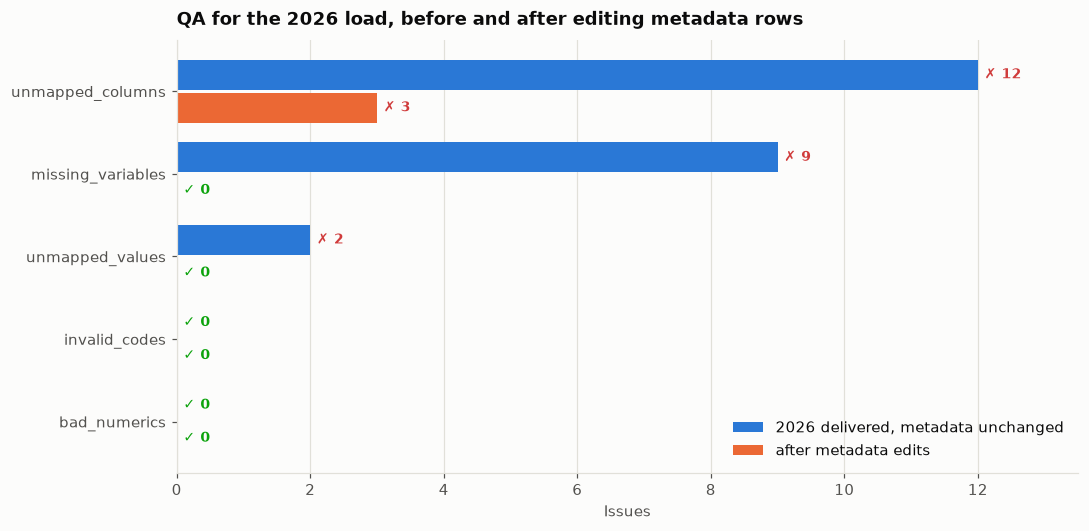

In [27]:
con = duckdb.connect()
build.build(con, META, RAW)
qa_2026_fixed = qa(con)
plot_qa({"2026 delivered, metadata unchanged": qa_2026_raw,
         "after metadata edits": qa_2026_fixed},
        "QA for the 2026 load, before and after editing metadata rows")

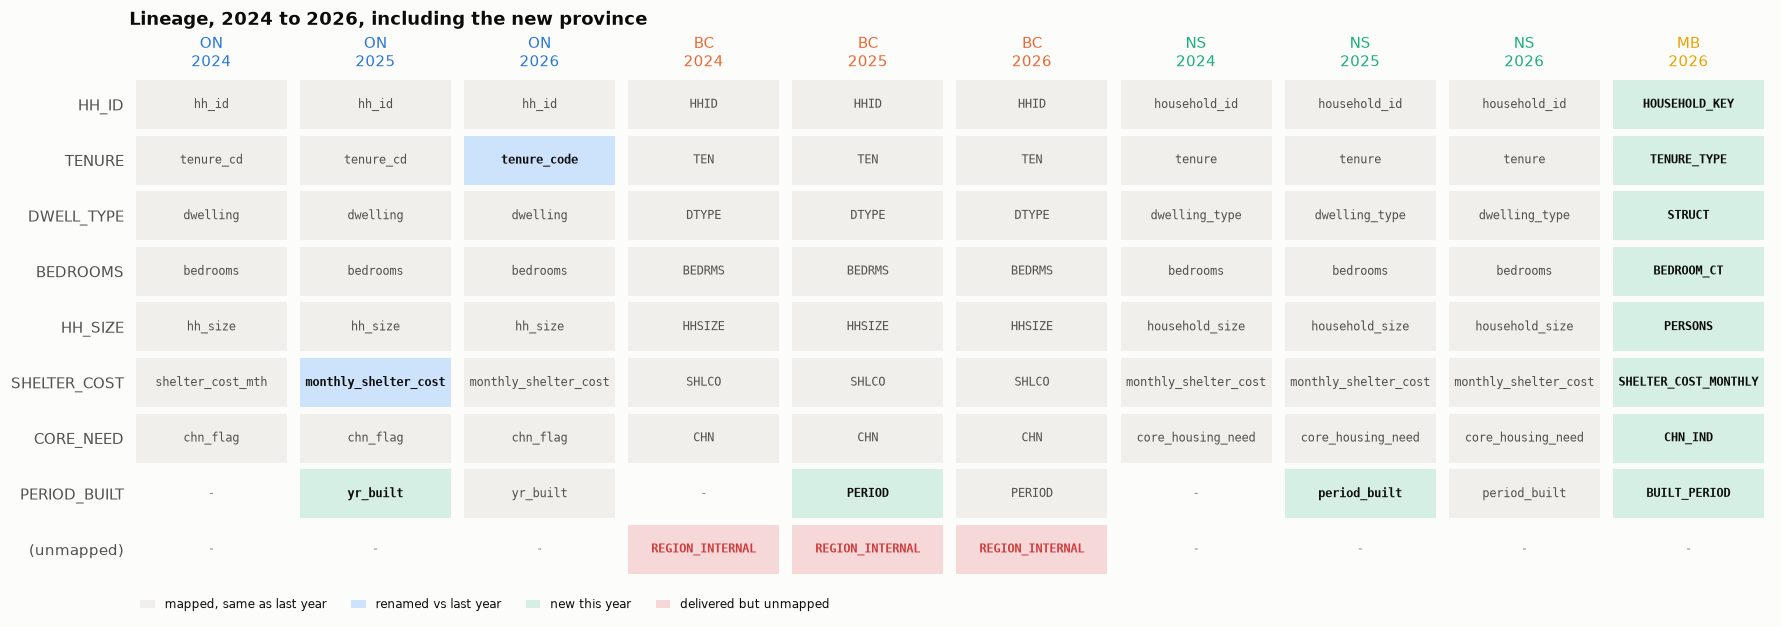

In [28]:
plot_lineage(con, "Lineage, 2024 to 2026, including the new province")

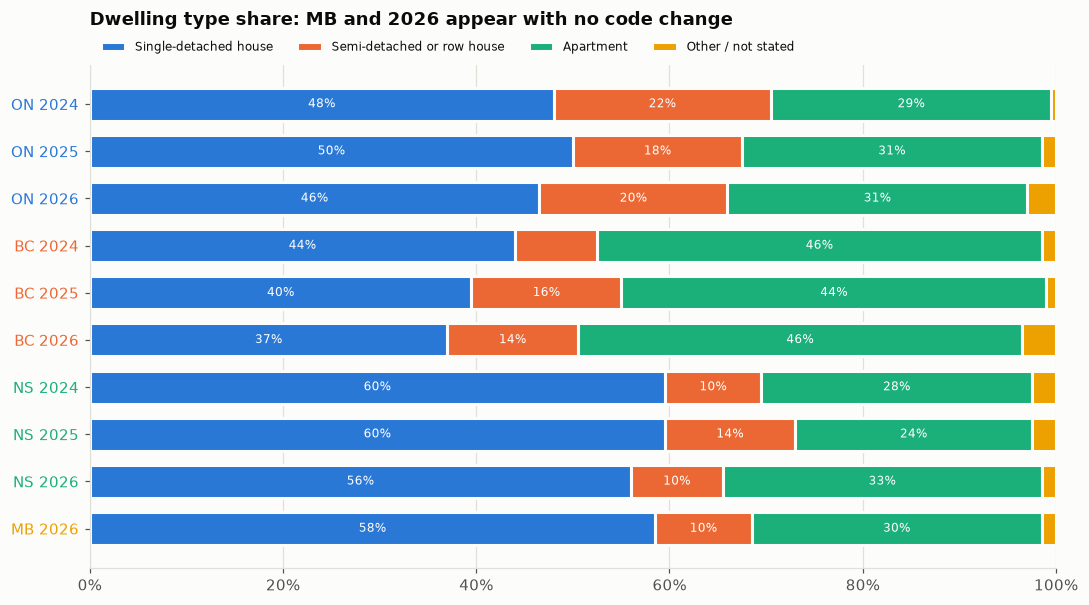

In [29]:
plot_dwelling(con, "Dwelling type share: MB and 2026 appear with no code change")

The 2026 data, the rename and a whole new province now flow through every view,
chart and QA check. The work was the **24 reviewed CSV rows** listed above.

The remaining two issues are BC's `REGION_INTERNAL` column. That points to a real gap
in the current model: **there is no way to say "we know about this column and are
ignoring it on purpose"**. Any unmapped column counts as a QA failure forever. See
*Known limitations* in the README for the suggested fix (an explicit "ignore" mapping).

### A note on partial reloads

`housing-build --year 2026` reloads only 2026 and leaves earlier years alone. That
keeps annual runs fast, but `record_value` stores the **recoded** value. So when a
metadata fix also applies to an *earlier* year (like BC's code `3`, valid from 2025),
those years must be reloaded too:

In [30]:
con = duckdb.connect()
build.build(con, META_BEFORE, RAW)                 # production DB as it stood before the edits
print()
build.build(con, META, RAW, years={2026})          # annual run: 2026 only
print("\nStill unmapped after a 2026-only reload:")
display(q(con, "SELECT * FROM meta.v_qa_unmapped_values"))

Reference metadata


  meta.codeset                4 rows
  meta.code                  12 rows


  meta.variable               8 rows
  meta.source_column_map     25 rows


  meta.source_code_map       21 rows
Datasets


  BC_2024     200 records   6 variables     1200 values


  NS_2024     200 records   6 variables     1200 values


... (15 outputs left out)

  ON_2026     200 records   7 variables     1400 values


QA summary


  !!  unmapped_columns   3
  OK  missing_variables  0
  !!  unmapped_values    1
  OK  invalid_codes      0
  OK  bad_numerics       0

Still unmapped after a 2026-only reload:


,reference_year,source_system,dataset_id,variable_id,source_value,n_records
0,2025,BC,BC_2025,TENURE,3,3


In [31]:
build.build(con, META, RAW, years={2025, 2026})    # reload every year the fix touches
q(con, "SELECT * FROM meta.v_qa_unmapped_values")

Reference metadata


  meta.codeset                4 rows
  meta.code                  13 rows


  meta.variable               8 rows
  meta.source_column_map     34 rows
  meta.source_code_map       34 rows
Datasets


  BC_2025     200 records   7 variables     1400 values


  NS_2025     200 records   7 variables     1400 values


  ON_2025     200 records   7 variables     1400 values


... (3 outputs left out)

  ON_2026     200 records   7 variables     1400 values


QA summary


  !!  unmapped_columns   3
  OK  missing_variables  0
  OK  unmapped_values    0
  OK  invalid_codes      0
  OK  bad_numerics       0


,reference_year,source_system,dataset_id,variable_id,source_value,n_records


**Rule of thumb:** after changing a mapping with `valid_from_year` earlier than the
current year, run `housing-build --year <every affected year>`, or just do a full
rebuild (seconds at this scale).

## Summary

| Without the model | With the model |
|---|---|
| Province-specific column names and recodes in code | Rows in `source_column_map` / `source_code_map` |
| `if year >= 2025` branches for renames | `valid_from_year` / `valid_to_year` on a row |
| New province = new code path | New province = mapping rows, same code |
| Problems found by analysts, late | Problems found by QA views, at load time, with the exact fix |
| Lineage reconstructed by hand | `dataset_column` records it on every load |
| Labels joined ad hoc per analysis | `v_record_labelled` / `v_data_dictionary` for everyone |

In [32]:
shutil.rmtree(WORK)   # tidy up the temporary working copy